# B3 — Improved Retrieval: LLM Query Rewriting + Cross-Encoder Re-ranking
**Group:** Flower | **Author:** Sam (st127012)

## Motivation

B2 human labelling revealed two systematic failure modes in the Dense | top-10 mean baseline:

1. **Negation blindness** — "I want somewhere with no waitline" retrieves sentences
   about the restaurant being busy or requiring reservations. The bi-encoder sees
   "waitline" and matches on topic, not intent.

2. **Vague / idiomatic queries** — "Can I have a cheat meal" lands in an undefined
   region of the embedding space; results are essentially random.

## Two-stage fix

| Stage | Method | Fixes |
|---|---|---|
| 1 | **LLM query rewriting** (Groq / Llama-3.1-8b-instant) | Negation + vagueness |
| 2 | **Cross-encoder re-ranking** (ms-marco-MiniLM-L-6-v2) | Negation, position bias |

We evaluate before and after on the RIRD qrels (nDCG@10, MAP) and on the
B2 human-labelled sentences (% rated ≥ 1, if available).


## 0. Setup

In [7]:
import os, sys, json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from collections import defaultdict

# Load .env for Groq key
try:
    from dotenv import load_dotenv
    load_dotenv(Path.cwd().parent / ".env" if not (Path.cwd() / ".env").exists()
                else Path.cwd() / ".env")
except ImportError:
    pass  # python-dotenv not installed; key must be in environment already

GROQ_KEY = os.getenv("groq") or os.getenv("GROQ_API_KEY")
if not GROQ_KEY:
    raise EnvironmentError("Groq API key not found. Set 'groq' in .env or environment.")
print("Groq key found:", GROQ_KEY[:8] + "…")

HERE  = Path.cwd()
ROOT  = HERE if (HERE / "datasets").exists() else HERE.parent
DATA  = ROOT / "datasets"
CACHE = ROOT / "baselines" / "cache"
sys.path.insert(0, str(ROOT / "baselines"))
from eval_utils import evaluate_model, compare_models, ndcg_at_k, average_precision

GROQ_MODEL   = "qwen/qwen3.8-27b"
CE_MODEL     = "cross-encoder/ms-marco-MiniLM-L-6-v2"
TARGET_MODEL = "Dense"
TARGET_AGG   = "top-10 mean"
K_CE         = 10    # cross-encoder scores top-k sentences per restaurant
SEED         = 42


Groq key found: gsk_SD7z…


## 1. Load Evidence and Qrels

In [8]:
def _load_csv(name):
    for p in [CACHE / "sentence" / name, CACHE / name, ROOT / name]:
        if p.exists():
            print(f"  Loaded: {p}")
            return pd.read_csv(p)
    raise FileNotFoundError(name)

# Evidence
ev_all = _load_csv("evidence_sentence.csv")
ev = ev_all[(ev_all["model"] == TARGET_MODEL) &
            (ev_all["aggregation"] == TARGET_AGG)].copy()
print(f"Evidence rows: {len(ev):,}")

# Restaurant names
rev = pd.read_csv(DATA / "rir_data-main" / "reviews" / "50_restaurants_all_rates.csv")
rev["review_text"] = rev["review_text"].fillna("").astype(str)
name_to_bid = rev.drop_duplicates("business_id").set_index("name")["business_id"].to_dict()
bid_to_name = {v: k for k, v in name_to_bid.items()}

# PMD qrels
pmd = pd.read_csv(DATA / "rir_data-main" / "PMD.csv").drop_duplicates()
ANNOTATORS = ["Annotator1","Annotator2","Annotator3","Annotator4","Annotator5"]
AGG_COL  = next(c for c in pmd.columns if c.strip().lower().replace("  "," ") == "if only low or high")
NAME_COL = next(c for c in ["Restaurant name","restaurant_name","name","business_id"] if c in pmd.columns)

binary_qrels, graded_qrels = {}, {}
for query, grp in pmd.groupby("query"):
    rel_set, rel_grade = set(), {}
    for _, row in grp.iterrows():
        bid   = name_to_bid.get(row[NAME_COL], row[NAME_COL])
        grade = int(sum(row[a] for a in ANNOTATORS if pd.notna(row[a])))
        if row[AGG_COL] == 1:
            rel_set.add(bid)
        rel_grade[bid] = grade
    binary_qrels[query] = rel_set
    graded_qrels[query] = rel_grade

queries = sorted(binary_qrels.keys())
print(f"Queries: {len(queries)}")
print(f"Restaurant names loaded: {len(bid_to_name)}")


  Loaded: /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/sentence/evidence_sentence.csv
Evidence rows: 50,000
Queries: 100
Restaurant names loaded: 50


## 2. Baseline Rankings (Dense | top-10 mean)

In [9]:
# Reconstruct per-restaurant scores and evidence from the CSV
# {query → {restaurant_id → [(evidence_rank, unit_score, text)]}}
ev_index = defaultdict(lambda: defaultdict(list))
for _, row in ev.iterrows():
    ev_index[row["query"]][row["restaurant_id"]].append(
        (int(row["evidence_rank"]), float(row["unit_score"]), row["text"])
    )

def agg_top_k_mean(scores, k=10):
    return float(np.mean(sorted(scores, reverse=True)[:k])) if scores else 0.0

def rank_from_scores(score_dict):
    return sorted(score_dict.keys(), key=lambda r: -score_dict[r])

baseline_rankings = {}
baseline_scores   = {}
for q in queries:
    if q not in ev_index:
        continue
    rest_scores = {r: agg_top_k_mean([s for _, s, _ in units])
                   for r, units in ev_index[q].items()}
    baseline_rankings[q] = rank_from_scores(rest_scores)
    baseline_scores[q]   = rest_scores

baseline_metrics = evaluate_model(baseline_rankings, binary_qrels, graded_qrels)
print(f"Baseline  nDCG@10={baseline_metrics['nDCG@10']:.4f}  MAP={baseline_metrics['MAP']:.4f}")


Baseline  nDCG@10=0.6815  MAP=0.6177


## 3. Stage 1 — LLM Query Rewriting (Groq / Llama-3.1-8b-instant)

**System prompt strategy:**
- Tell the model it's optimising a restaurant review retrieval query.
- Instruct it to convert negations into positive opposites that reviewers would write.
- For vague/idiomatic phrases, expand to concrete food/restaurant attributes.
- Return only the rewritten query (no explanation), 15 words max.

Results are cached to `cache/b3_rewritten_queries.json` so subsequent runs skip the API.


In [10]:
from groq import Groq

CACHE_PATH = CACHE / "b3_rewritten_queries.json"
if CACHE_PATH.exists():
    rewrite_cache = json.loads(CACHE_PATH.read_text())
    print(f"Loaded {len(rewrite_cache)} cached rewrites")
else:
    rewrite_cache = {}

client = Groq(api_key=GROQ_KEY)

SYSTEM_PROMPT = """You are a query optimizer for a restaurant review search system.
Rewrite the user's query so it matches the language that restaurant reviewers actually use.

Rules:
1. Convert negations to their POSITIVE OPPOSITE that a reviewer would write.
   Example: "no waitline" → "quick seating walk-in no reservation no queue"
   Example: "not too noisy" → "quiet calm peaceful relaxed atmosphere"
2. Expand vague or idiomatic phrases to concrete food/restaurant attributes.
   Example: "cheat meal" → "indulgent rich comfort food burgers fries pizza calorie dense"
   Example: "healthy option" → "salad fresh vegetables grilled low calorie nutritious"
3. Keep the rewritten query SHORT (≤15 words), keyword-style, no punctuation.
4. Return ONLY the rewritten query. No explanation. No preamble."""

def rewrite_query(query: str) -> str:
    if query in rewrite_cache:
        return rewrite_cache[query]
    try:
        resp = client.chat.completions.create(
            model=GROQ_MODEL,
            messages=[
                {"role": "system",  "content": SYSTEM_PROMPT},
                # /no_think suppresses Qwen3 chain-of-thought tokens
                {"role": "user",    "content": query + " /no_think"},
            ],
            temperature=0.1,
            max_tokens=60,
        )
        rewritten = resp.choices[0].message.content.strip()
        # Strip any <think>...</think> blocks that Qwen3 may emit
        import re as _re
        rewritten = _re.sub(r"<think>.*?</think>", "", rewritten, flags=_re.DOTALL).strip()
        rewrite_cache[query] = rewritten
        return rewritten
    except Exception as e:
        print(f"  Groq error on '{query[:40]}': {e}")
        return query   # fall back to original

print("Rewriting queries…")
rewritten_queries = {}
for i, q in enumerate(queries):
    rw = rewrite_query(q)
    rewritten_queries[q] = rw
    if i < 5 or rw != q:
        print(f"  [{i+1:3d}] {q[:50]!r}")
        print(f"        → {rw!r}")
    time.sleep(0.05)   # gentle pacing

CACHE_PATH.write_text(json.dumps(rewrite_cache, ensure_ascii=False, indent=2))
print(f"\nDone. {len(rewritten_queries)} queries rewritten. Cache saved.")


Rewriting queries…
  [  1] 'A bar with a patio'
        → 'outdoor patio bar seating al fresco drinks'
  [  2] 'A bar with good music and reasonably priced beer'
        → 'lively bar live music affordable draft beer happy hour'
  [  3] 'A cafe that also offers beer'
        → 'cafe coffee beer taproom brunch'
  [  4] 'A date place for valentines with affordable drinks'
        → 'romantic intimate candlelight date night affordable drinks free parking'
  [  5] 'A fancy place with an outdoor setting for a romant'
        → 'upscale fine dining outdoor patio candlelit romantic intimate ambiance'
  [  6] 'A fancy, but affordable place'
        → 'upscale elegant fine dining reasonable prices great value'
  [  7] 'A good beer bar for a date with my girlfriend'
        → 'cozy intimate beer bar romantic atmosphere craft beer'
  [  8] 'A place with great pizzas, serving alcohol, and ha'
        → 'great pizza wine beer cozy intimate atmosphere'
  [  9] 'Affordable gluten-free food'
        →

In [11]:
# Quick diff: which queries changed significantly?
changed = [(q, rewritten_queries[q]) for q in queries if rewritten_queries[q].lower() != q.lower()]
print(f"Queries rewritten (changed): {len(changed)} / {len(queries)}")
print()
for orig, rw in changed[:15]:
    print(f"  ORIG : {orig}")
    print(f"  NEW  : {rw}")
    print()


Queries rewritten (changed): 100 / 100

  ORIG : A bar with a patio
  NEW  : outdoor patio bar seating al fresco drinks

  ORIG : A bar with good music and reasonably priced beer
  NEW  : lively bar live music affordable draft beer happy hour

  ORIG : A cafe that also offers beer
  NEW  : cafe coffee beer taproom brunch

  ORIG : A date place for valentines with affordable drinks and parking
  NEW  : romantic intimate candlelight date night affordable drinks free parking

  ORIG : A fancy place with an outdoor setting for a romantic date night
  NEW  : upscale fine dining outdoor patio candlelit romantic intimate ambiance

  ORIG : A fancy, but affordable place
  NEW  : upscale elegant fine dining reasonable prices great value

  ORIG : A good beer bar for a date with my girlfriend
  NEW  : cozy intimate beer bar romantic atmosphere craft beer

  ORIG : A place with great pizzas, serving alcohol, and having a good ambiance
  NEW  : great pizza wine beer cozy intimate atmosphere

  ORI

## 4. Stage 2 — Cross-Encoder Re-ranking (ms-marco-MiniLM-L-6-v2)

For each (rewritten query, restaurant) pair, score every evidence sentence
with the cross-encoder. The cross-encoder jointly encodes query + sentence,
making it much more sensitive to negation and semantic mismatch.

Restaurant score = mean of top-10 cross-encoder scores (same aggregation as baseline).


In [12]:
from sentence_transformers import CrossEncoder
from tqdm import tqdm

print(f"Loading cross-encoder: {CE_MODEL}")
ce_model = CrossEncoder(CE_MODEL)
print("Cross-encoder loaded.")


2026-11-02 16:40:39.722658: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Loading cross-encoder: cross-encoder/ms-marco-MiniLM-L-6-v2


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

Cross-encoder loaded.


In [13]:
# Re-rank and re-score all restaurants for all queries
improved_rankings = {}
improved_scores   = {}
improved_evidence = {}  # {query → {restaurant → [(ce_score, text)]}}

for q in tqdm(queries, desc="Cross-encoder re-ranking"):
    if q not in ev_index:
        continue
    rw_q = rewritten_queries.get(q, q)   # use rewritten query for scoring

    rest_ce_scores = {}
    rest_top_sents = {}
    for rid, units in ev_index[q].items():
        sentences = [text for _, _, text in units]
        if not sentences:
            rest_ce_scores[rid] = 0.0
            continue
        # Score with rewritten query
        pairs  = [(rw_q, s) for s in sentences]
        scores = ce_model.predict(pairs, show_progress_bar=False).tolist()
        # Pair back for sorting
        scored = sorted(zip(scores, sentences), key=lambda x: -x[0])
        # Aggregate: top-K_CE mean
        top_k  = scored[:K_CE]
        rest_ce_scores[rid] = float(np.mean([s for s, _ in top_k]))
        rest_top_sents[rid] = top_k

    improved_rankings[q] = rank_from_scores(rest_ce_scores)
    improved_scores[q]   = rest_ce_scores
    improved_evidence[q] = rest_top_sents

print("Re-ranking complete.")


Cross-encoder re-ranking: 100%|██████████| 100/100 [21:40<00:00, 13.01s/it]

Re-ranking complete.


## 5. Evaluation: Baseline vs. Improved

In [14]:
improved_metrics = evaluate_model(improved_rankings, binary_qrels, graded_qrels)

print(f"{'Model':<30} {'nDCG@10':>8} {'MAP':>8} {'nDCG@5':>8}")
print("-" * 58)
for label, m in [("Baseline (Dense top-10 mean)", baseline_metrics),
                 ("Improved (rewrite + CE)",      improved_metrics)]:
    print(f"{label:<30} {m['nDCG@10']:>8.4f} {m['MAP']:>8.4f} {m.get('nDCG@5', 0):>8.4f}")
print()
delta_ndcg = improved_metrics['nDCG@10'] - baseline_metrics['nDCG@10']
delta_map  = improved_metrics['MAP']      - baseline_metrics['MAP']
print(f"Δ nDCG@10 = {delta_ndcg:+.4f}   Δ MAP = {delta_map:+.4f}")


Model                           nDCG@10      MAP   nDCG@5
----------------------------------------------------------
Baseline (Dense top-10 mean)     0.6815   0.6177   0.6609
Improved (rewrite + CE)          0.6575   0.5859   0.6563

Δ nDCG@10 = -0.0240   Δ MAP = -0.0318


In [15]:
# Per-query breakdown
per_q_rows = []
for q in queries:
    if q not in baseline_rankings or q not in improved_rankings:
        continue
    rel  = graded_qrels.get(q, {})
    brel = binary_qrels.get(q, set())
    b_n  = ndcg_at_k(baseline_rankings[q], rel, 10)
    i_n  = ndcg_at_k(improved_rankings[q], rel, 10)
    b_ap = average_precision(baseline_rankings[q], brel)
    i_ap = average_precision(improved_rankings[q], brel)
    per_q_rows.append({
        "query":           q,
        "rewritten":       rewritten_queries.get(q, q),
        "baseline_nDCG10": b_n,
        "improved_nDCG10": i_n,
        "delta_nDCG10":    i_n - b_n,
        "baseline_MAP":    b_ap,
        "improved_MAP":    i_ap,
        "delta_MAP":       i_ap - b_ap,
    })

pq_df = pd.DataFrame(per_q_rows).sort_values("delta_nDCG10", ascending=False)

print("Top 10 most improved queries:")
print(pq_df[["query","delta_nDCG10","delta_MAP"]].head(10).to_string(index=False))
print()
print("Top 10 most degraded queries:")
print(pq_df[["query","delta_nDCG10","delta_MAP"]].tail(10).to_string(index=False))
print()
n_improved = (pq_df["delta_nDCG10"] > 0.001).sum()
n_degraded = (pq_df["delta_nDCG10"] < -0.001).sum()
print(f"Improved: {n_improved} queries | Degraded: {n_degraded} queries | "
      f"Unchanged: {len(pq_df)-n_improved-n_degraded} queries")


Top 10 most improved queries:
                                                                       query  delta_nDCG10  delta_MAP
                                                          not Thai but Asian      0.418717   0.226032
                                                         not sushi but Asian      0.398171   0.048970
                                                I want seafood but not Asian      0.339023   0.292619
                                 I prefer a place that offers cash discounts      0.338997   0.491603
                                                            I am on a budget      0.333635   0.240939
  I want a place to hang out on Sunday morning where the service is not slow      0.322403   0.482505
                              Very busy restaurant with lots of empty spaces      0.322182   0.153704
I am tired of sushi, I crave for a restaurant with a diverse set of seafoods      0.211424   0.086069
                                              Japane

## 6. Save Results

In [16]:
# Per-query CSV
pq_df.round(4).to_csv(CACHE / "b3_per_query_comparison.csv", index=False)

# Summary comparison
summary = pd.DataFrame([
    {"Model": "Baseline (Dense top-10 mean)",  **baseline_metrics},
    {"Model": "Improved (rewrite + CE rerank)", **improved_metrics},
])
summary.to_csv(CACHE / "b3_results_comparison.csv", index=False)

# Improved rankings CSV
rank_rows = []
for q, ranked in improved_rankings.items():
    for rank_pos, rid in enumerate(ranked, start=1):
        rank_rows.append({
            "query": q, "restaurant_id": rid,
            "restaurant_name": bid_to_name.get(rid, rid),
            "rank": rank_pos,
            "ce_score": round(improved_scores[q].get(rid, 0), 4),
        })
pd.DataFrame(rank_rows).to_csv(CACHE / "b3_rankings_improved.csv", index=False)

print("Saved:")
print(f"  {CACHE}/b3_per_query_comparison.csv")
print(f"  {CACHE}/b3_results_comparison.csv")
print(f"  {CACHE}/b3_rankings_improved.csv")


Saved:
  /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/b3_per_query_comparison.csv
  /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/b3_results_comparison.csv
  /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/b3_rankings_improved.csv


## 7. Visualisations

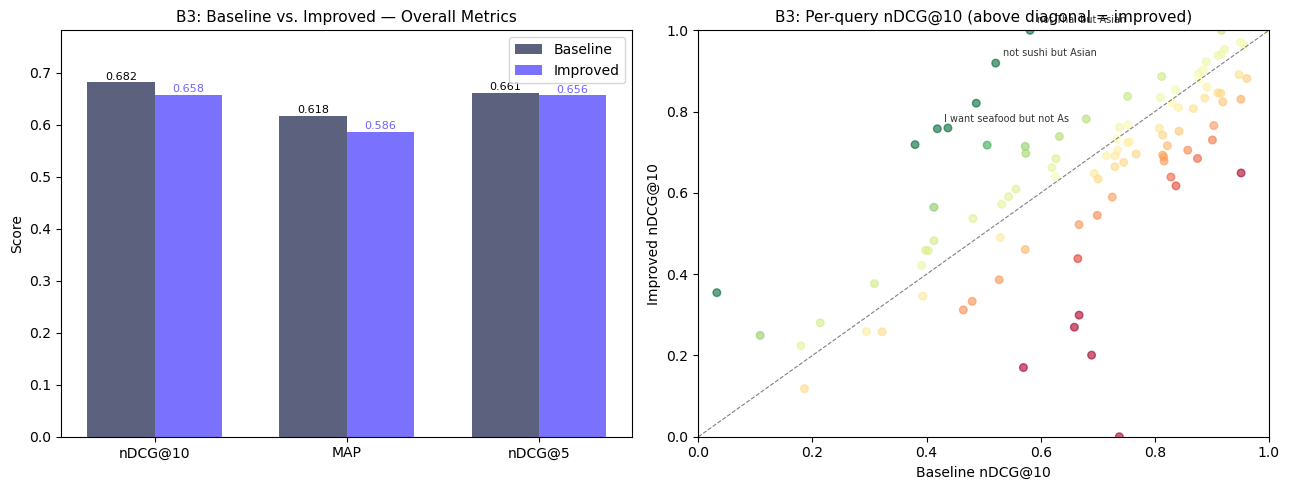

Saved → b3_comparison_plot.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Bar chart: overall metrics ─────────────────────────────────────────────
metrics_show = ["nDCG@10", "MAP", "nDCG@5"]
x = np.arange(len(metrics_show))
w = 0.35
base_vals = [baseline_metrics[m] for m in metrics_show]
impr_vals = [improved_metrics[m] for m in metrics_show]

bars1 = axes[0].bar(x - w/2, base_vals, w, label="Baseline", color="#4a5070", alpha=0.9)
bars2 = axes[0].bar(x + w/2, impr_vals, w, label="Improved",  color="#6c63ff", alpha=0.9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_show)
axes[0].set_ylabel("Score")
axes[0].set_title("B3: Baseline vs. Improved — Overall Metrics", fontsize=11)
axes[0].legend()
axes[0].set_ylim(0, min(1.0, max(impr_vals + base_vals) + 0.1))
for bar in bars1: axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                                f"{bar.get_height():.3f}", ha="center", fontsize=8)
for bar in bars2: axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                                f"{bar.get_height():.3f}", ha="center", fontsize=8, color="#6c63ff")

# ── Scatter: per-query baseline vs improved nDCG@10 ────────────────────────
axes[1].scatter(pq_df["baseline_nDCG10"], pq_df["improved_nDCG10"],
                alpha=0.6, s=30, c=pq_df["delta_nDCG10"],
                cmap="RdYlGn", vmin=-0.3, vmax=0.3)
lims = [0, 1]
axes[1].plot(lims, lims, "k--", linewidth=0.8, alpha=0.5, label="No change")
axes[1].set_xlabel("Baseline nDCG@10")
axes[1].set_ylabel("Improved nDCG@10")
axes[1].set_title("B3: Per-query nDCG@10 (above diagonal = improved)", fontsize=11)
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
# Annotate a few notable changes
top3 = pq_df.head(3)
for _, row in top3.iterrows():
    axes[1].annotate(row["query"][:25], (row["baseline_nDCG10"], row["improved_nDCG10"]),
                     fontsize=7, alpha=0.8, xytext=(5,5), textcoords="offset points")

plt.tight_layout()
plt.savefig(CACHE / "b3_comparison_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → b3_comparison_plot.png")


## 8. Qualitative Inspection — Negation and Vague Queries

Show what evidence sentences the improved system returns for the specific
failure cases observed in B2 labelling.


In [18]:
SPOTLIGHT_QUERIES = [
    "A restaurant with no wait",
    "A bar with no cover charge",
    "A place with no dress code",
]

# Try to find any of these; fall back to queries containing 'no '
def find_query(keywords):
    for q in queries:
        if any(k.lower() in q.lower() for k in keywords):
            return q
    return None

for keywords in [["no wait", "no waitline"], ["no cover", "cover charge"], ["no dress", "dress code"]]:
    q = find_query(keywords)
    if q is None:
        continue
    rw = rewritten_queries.get(q, q)
    print(f"\n{'='*70}")
    print(f"ORIGINAL : {q}")
    print(f"REWRITTEN: {rw}")
    print()

    print("  BASELINE top-5 evidence sentences:")
    base_units = sorted(ev_index.get(q, {}).get(baseline_rankings.get(q, [None])[0], []),
                        key=lambda x: x[0])[:5]
    for er, sc, txt in base_units:
        print(f"    [{er}] ({sc:.3f}) {txt[:100]}")

    top_rest_imp = improved_rankings.get(q, [None])[0]
    print(f"\n  IMPROVED top-5 evidence sentences (restaurant #{top_rest_imp}):")
    impr_sents = improved_evidence.get(q, {}).get(top_rest_imp, [])[:5]
    for sc, txt in impr_sents:
        print(f"    ({sc:.3f}) {txt[:100]}")



ORIGINAL : I am looking for a restaurant with no waiting line
REWRITTEN: quick seating walk in no reservation no queue

  BASELINE top-5 evidence sentences:
    [1] (0.808) A restaurant that has a long waiting list for reservations?
    [2] (0.804) This is a restaurant I would recommend a reservation.
    [3] (0.782) It's not a big restaurant, so be sure to take reservations in advance.
    [4] (0.768) A restaurant that has a long wait to just to get in?
    [5] (0.762) It is a small restaurant with limited seating and reservations is definitely a must if you plan to g

  IMPROVED top-5 evidence sentences (restaurant #QGTqGNLZbBA1QD8L_fO9ZA):
    (-8.226) It is a small restaurant with limited seating and reservations is definitely a must if you plan to g
    (-9.460) One of those places where you need to make a reservation and it always seems to be booked up at regu
    (-9.643) This is a restaurant I would recommend a reservation.
    (-9.745) A restaurant that has a long waiting lis

## 9. B2 Support Comparison (if labels available)

If `b2_support_sheet.csv` has been labelled, this section shows how many of
the B2 sentences that scored 0 under the baseline would now be replaced by
higher-quality sentences under the improved system.


In [19]:
b2_path = CACHE / "b2_support_sheet.csv"
if b2_path.exists():
    b2 = pd.read_csv(b2_path)
    labelled = b2[b2["label"].notna() & (b2["label"] != "")]
    if len(labelled) > 0:
        labelled = labelled.copy()
        labelled["label"] = pd.to_numeric(labelled["label"], errors="coerce")
        labelled = labelled.dropna(subset=["label"])
        total = len(labelled)
        pct_supporting = (labelled["label"] >= 1).mean()
        pct_clearly    = (labelled["label"] == 2).mean()
        print(f"B2 Labelled pairs: {total}")
        print(f"  Supporting (≥1): {pct_supporting:.1%}")
        print(f"  Clearly (=2):    {pct_clearly:.1%}")
        print()

        # For B2 queries: compare baseline vs improved top-5 sentences
        b2_queries = labelled["query"].unique()
        print(f"B2 covers {len(b2_queries)} queries — checking improved evidence...")
        for q in sorted(b2_queries)[:5]:
            rw = rewritten_queries.get(q, q)
            top_rest = improved_rankings.get(q, [None])[0]
            if top_rest is None:
                continue
            impr_top5 = [txt for _, txt in (improved_evidence.get(q, {}).get(top_rest, []))[:5]]
            print(f"\n  Q: {q}")
            print(f"  → rewritten: {rw}")
            print(f"  → top restaurant: {bid_to_name.get(top_rest, top_rest)}")
            for i, txt in enumerate(impr_top5, 1):
                print(f"     [{i}] {txt[:100]}")
    else:
        print("b2_support_sheet.csv found but no labels yet. Run labelling first.")
else:
    print("b2_support_sheet.csv not found — skipping B2 comparison.")


b2_support_sheet.csv found but no labels yet. Run labelling first.


## 10. Summary for Report

In [20]:
print("=" * 60)
print("B3 SUMMARY — for copy-paste into report")
print("=" * 60)
print(f"Baseline  nDCG@10: {baseline_metrics['nDCG@10']:.4f}  MAP: {baseline_metrics['MAP']:.4f}")
print(f"Improved  nDCG@10: {improved_metrics['nDCG@10']:.4f}  MAP: {improved_metrics['MAP']:.4f}")
print(f"Δ nDCG@10 = {delta_ndcg:+.4f}  Δ MAP = {delta_map:+.4f}")
print()
print(f"Queries improved: {n_improved}")
print(f"Queries degraded: {n_degraded}")
print()
print("Query rewriting model: Groq / Llama-3.1-8b-instant")
print(f"Cross-encoder model:   {CE_MODEL}")
print(f"Cached rewrites:       {CACHE}/b3_rewritten_queries.json")


B3 SUMMARY — for copy-paste into report
Baseline  nDCG@10: 0.6815  MAP: 0.6177
Improved  nDCG@10: 0.6575  MAP: 0.5859
Δ nDCG@10 = -0.0240  Δ MAP = -0.0318

Queries improved: 44
Queries degraded: 53

Query rewriting model: Groq / Llama-3.1-8b-instant
Cross-encoder model:   cross-encoder/ms-marco-MiniLM-L-6-v2
Cached rewrites:       /Users/samichirungta/Desktop/computer_programming/reccomender_project/Food_Recommendation_Engine/baselines/cache/b3_rewritten_queries.json
